# 05 - Explainable AI (SHAP)

Exact Shapley values of the deployed model's calibrated probability, relative to a 50-patient training background. SHAP values are **model contributions, not clinical causes**.

In [1]:
import sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown
from src.config import load_config
cfg = load_config()
M = cfg.path("paths", "metrics_dir"); F = cfg.path("paths", "figures_dir")
pd.set_option("display.precision", 4); pd.set_option("display.width", 200)
def show(name): display(Image(filename=str(F / name)))

In [2]:
pd.read_csv(M / 'shap_global_importance.csv')

,feature,mean_abs_shap,mean_shap
0,Glucose,0.1471,-0.0134
1,BMI,0.0745,0.0091
2,Age,0.0465,-0.0002
3,DiabetesPedigreeFunction,0.0412,-0.0045
4,Insulin,0.0257,0.0084
5,Pregnancies,0.0227,0.0055
6,SkinThickness,0.0149,-0.0035
7,BloodPressure,0.0093,0.0005


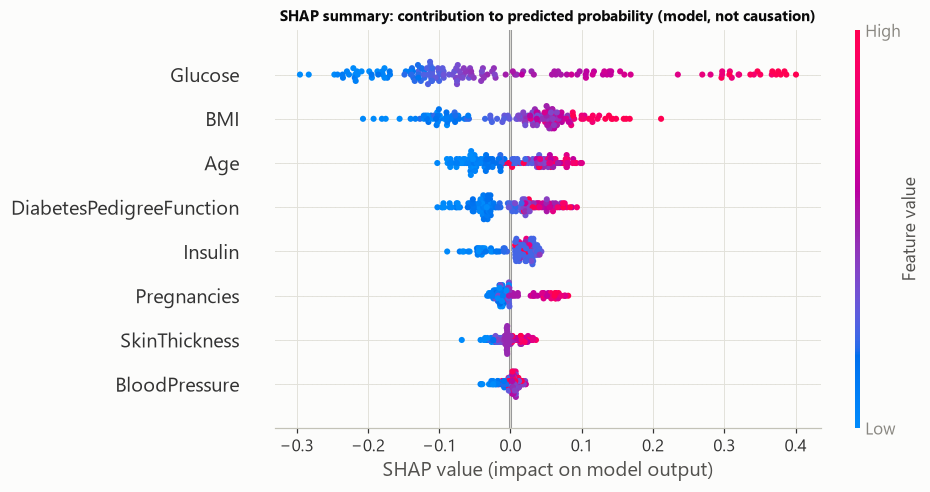

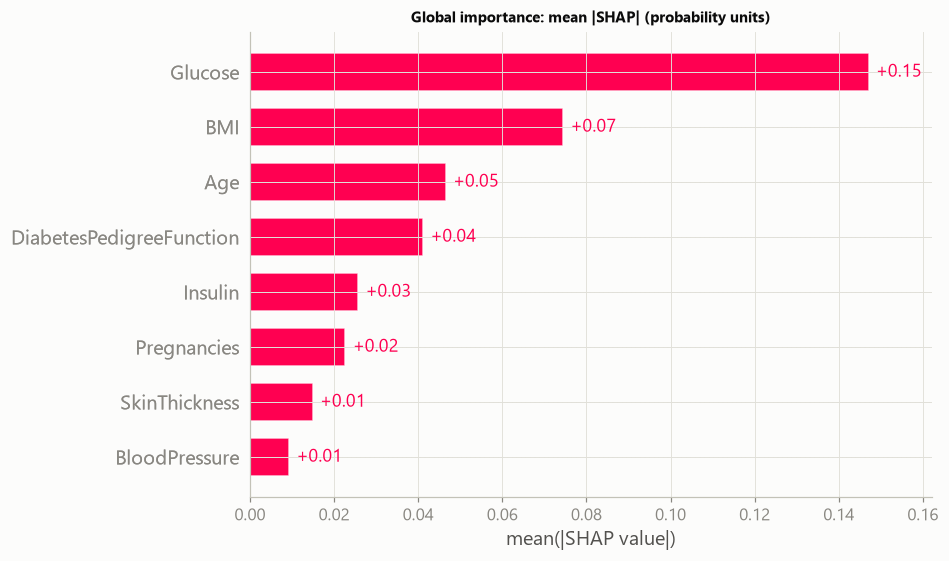

In [3]:
show('shap_summary_beeswarm.png'); show('shap_bar.png')

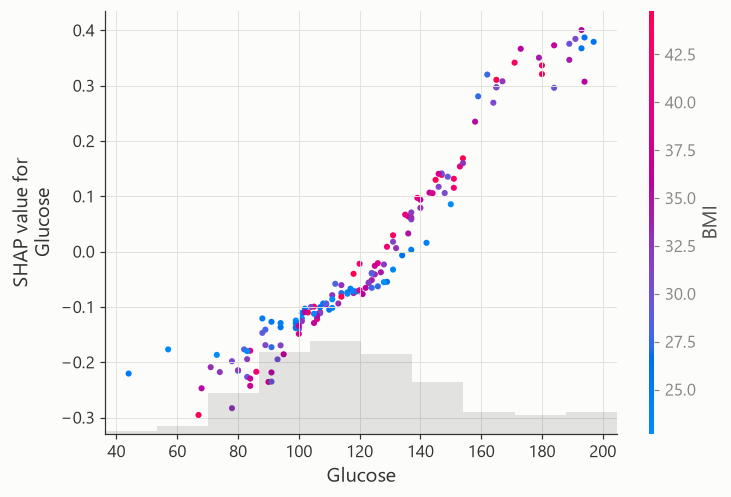

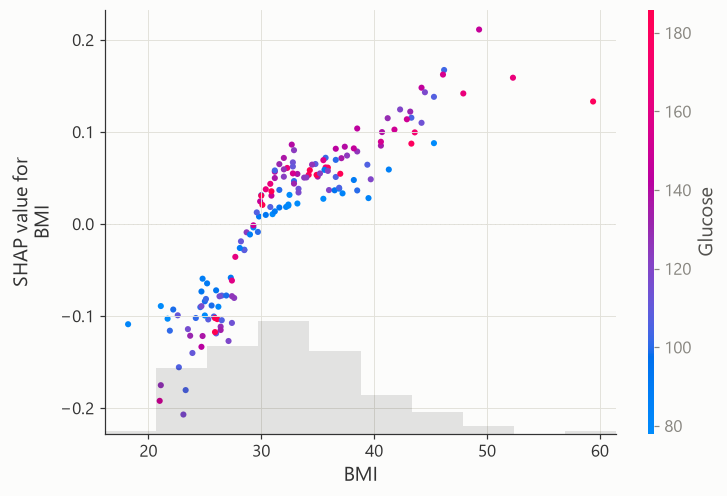

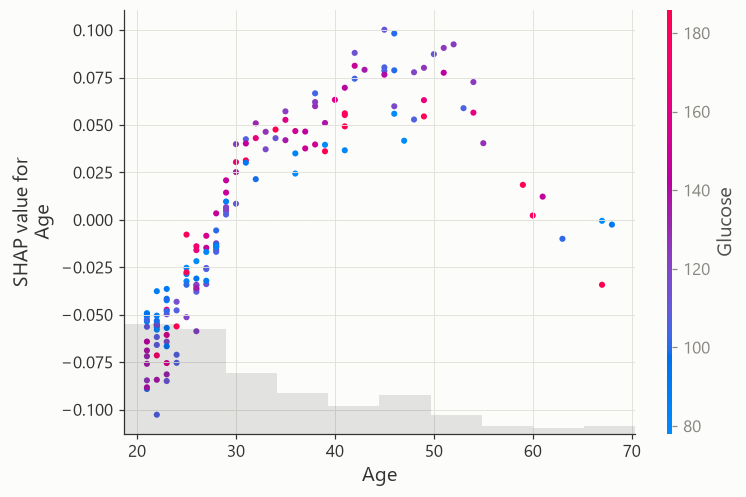

In [4]:
for f in ['Glucose', 'BMI', 'Age']: show(f'shap_dependence_{f}.png')

## Individual explanation (live)

In [5]:
from src.inference.predictor import DiabetesPredictor
from src.inference.schemas import PatientFeatures
pred = DiabetesPredictor.from_config(cfg)
res = pred.predict(PatientFeatures(pregnancies=2, glucose=140, blood_pressure=80, skin_thickness=25, insulin=100, bmi=30.5, diabetes_pedigree=0.45, age=40))
print(res['risk_statement'], '| p =', res['probability'], '| threshold =', res['threshold'])
pd.DataFrame(res['explanation']['contributions'])

The model predicts a higher likelihood of diabetes based on the supplied features. | p = 0.4645 | threshold = 0.32


,feature,value,imputed,shap_value,direction,display_name,unit
0,Glucose,140.00,False,0.0660,increases,Glucose (2-h OGTT),mg/dL
1,Age,40.00,False,0.0617,increases,Age,years
2,Insulin,100.00,False,-0.0468,decreases,2-hour serum insulin,uU/mL
3,BMI,30.50,False,0.0317,increases,BMI,kg/m^2
4,SkinThickness,25.00,False,-0.0196,decreases,Triceps skinfold thickness,mm
5,DiabetesPedigreeFunction,0.45,False,0.0193,increases,Diabetes pedigree function,score
6,BloodPressure,80.00,False,0.0142,increases,Diastolic blood pressure,mm Hg
7,Pregnancies,2.00,False,-0.0141,decreases,Pregnancies,count


In [6]:
c = res['explanation']
print('base + sum(SHAP) =', round(c['base_value'] + sum(x['shap_value'] for x in c['contributions']), 4), 'vs probability', res['probability'])
print(c['summary'])

base + sum(SHAP) = 0.4645 vs probability 0.4645
The model's estimated probability is 0.46, which is above the balanced threshold of 0.32. Inputs that raised the model's estimate the most: Glucose (2-h OGTT) = 140 mg/dL (+0.066); Age = 40 years (+0.062); BMI = 30.5 kg/m^2 (+0.032). Inputs that lowered it the most: 2-hour serum insulin = 100 uU/mL (-0.047); Triceps skinfold thickness = 25 mm (-0.020); Pregnancies = 2 (-0.014). These are model contributions, not causes.


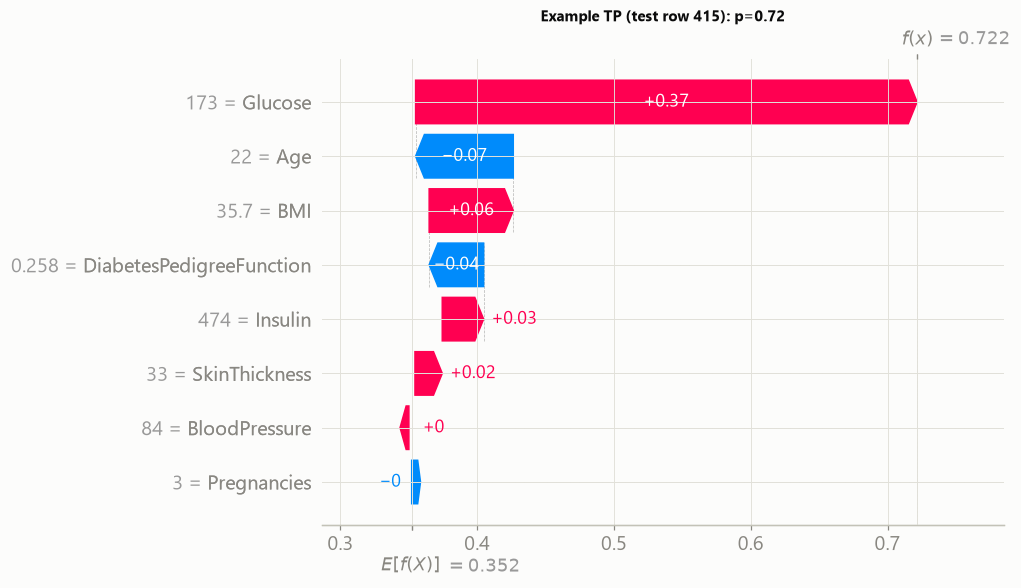

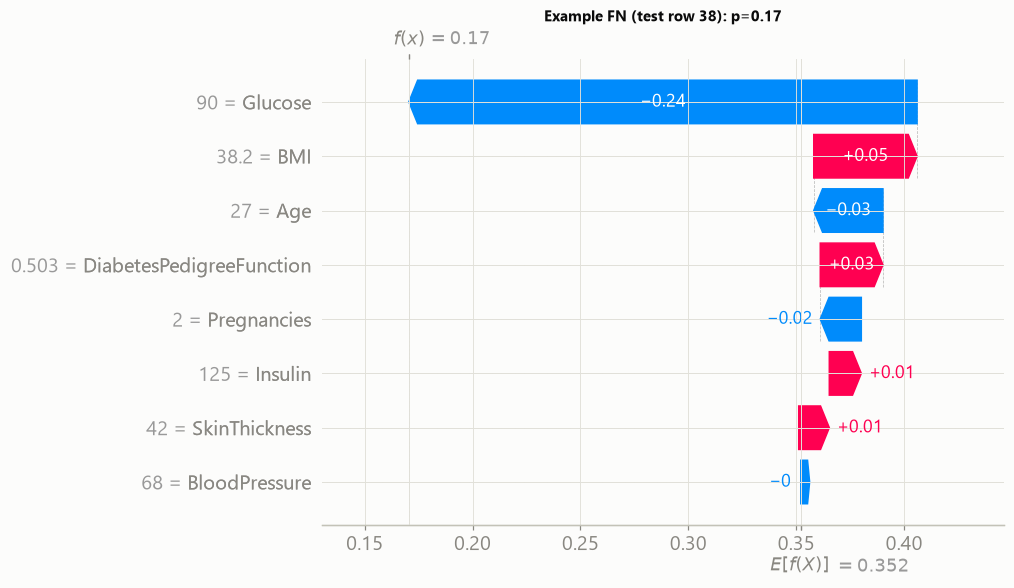

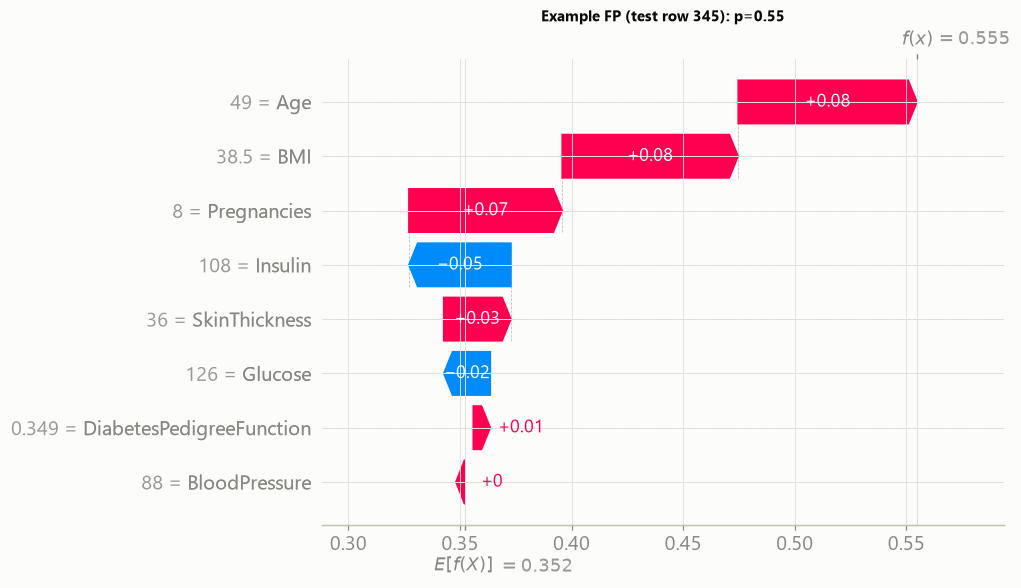

In [7]:
for et in ['TP', 'FN', 'FP']: show(f'shap_waterfall_{et}.png')

## Complementary views

In [8]:
display(pd.read_csv(M / 'permutation_importance_test.csv'))
display(pd.read_csv(M / 'native_importances_base_learners.csv', index_col=0))

,feature,pr_auc_drop_mean,pr_auc_drop_std
0,Glucose,0.1635,0.0568
1,Age,0.0625,0.0262
2,BMI,0.0551,0.0255
3,DiabetesPedigreeFunction,0.0267,0.0144
4,Pregnancies,0.0239,0.0070
5,SkinThickness,0.0058,0.0061
6,BloodPressure,0.0011,0.0053
7,Insulin,0.0009,0.0139


,xgboost,extratrees,catboost
Pregnancies,0.0962,0.0633,0.0408
Glucose,0.2426,0.4540,0.3561
BloodPressure,0.0814,0.0372,0.0469
SkinThickness,0.0964,0.0554,0.0454
Insulin,0.1225,0.0489,0.0559
BMI,0.1417,0.1594,0.2096
DiabetesPedigreeFunction,0.0966,0.0457,0.1215
Age,0.1227,0.1362,0.1237
